In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.ticker import FuncFormatter

import warnings
warnings.filterwarnings('ignore')

In [2]:
sns.set_style("whitegrid")
plt.rcParams['figure.figsize'] = (12, 6)
plt.rcParams['axes.titlesize'] = 13
plt.rcParams['axes.titleweight'] = 'bold'

In [3]:
#دالة لجعل القيم تبدو بشكل المليون والألف ومليار بدلا من كتابة ألأرقام بشكلها الكبير فقط
def human_format(x, pos=None):
    if abs(x) >= 1e9: return f'{x/1e9:.1f}B'
    if abs(x) >= 1e6: return f'{x/1e6:.1f}M'
    if abs(x) >= 1e3: return f'{x/1e3:.0f}K'
    return f'{x:.0f}'

In [4]:
file_path = r'C:\Users\Afaq_Lite\Downloads\country_stats.csv'
df = pd.read_csv(file_path)
df.columns = df.columns.str.strip()

In [5]:
df.head()

,Country name,Total in km2,Land in km2,Inland water in km2,% water,Population,% of world population,Population density,HDI,Fertility rate,Mortality rate,% of internet users in population,External debt (billions)
0,Russia,17098246.0,16376870.0,721380.0,4.2,1.460283e+08,1.8,8.54,0.832,1.47,13.27,95.6,299.0637
1,Canada,9984670.0,9093507.0,891163.0,8.9,4.141706e+07,0.5,4.15,0.939,1.33,8.17,94.4,"3,468.2119"
2,China,9596960.0,9326410.0,270550.0,2.8,1.404890e+09,17.0,146.39,0.797,1.03,7.82,91.6,"2,412.0799"
3,United States,9525067.0,9147593.0,377424.0,4.0,3.417849e+08,4.1,35.88,0.938,1.63,8.42,94.7,"30,196.961"
4,Brazil,8510346.0,8460415.0,55352.0,0.6,2.142120e+08,2.6,25.17,0.786,1.59,6.90,84.5,692.6895


In [6]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 195 entries, 0 to 194
Data columns (total 13 columns):
 #   Column                             Non-Null Count  Dtype  
---  ------                             --------------  -----  
 0   Country name                       195 non-null    object 
 1   Total in km2                       195 non-null    float64
 2   Land in km2                        194 non-null    float64
 3   Inland water in km2                194 non-null    float64
 4   % water                            194 non-null    float64
 5   Population                         194 non-null    float64
 6   % of world population              194 non-null    float64
 7   Population density                 194 non-null    float64
 8   HDI                                190 non-null    float64
 9   Fertility rate                     191 non-null    float64
 10  Mortality rate                     187 non-null    float64
 11  % of internet users in population  189 non-null    float64

In [7]:
#تعغيير اسماء الأعمدة ليسهل التعامل معها
rename_map = {
    'Country name': 'Country',
    'Total in km2': 'Total_km2',
    'Land in km2': 'Land_km2',
    'Inland water in km2': 'Water_km2',
    '% water': 'Water_pct',
    'Population': 'Population',
    '% of world population': 'World_pop_pct',
    'Population density': 'Pop_density',
    'HDI': 'HDI',
    'Fertility rate': 'Fertility',
    'Mortality rate': 'Mortality',
    '% of internet users in population': 'Internet_pct',
    'External debt (billions)': 'External_debt_bn'}
df.rename(columns=rename_map, inplace=True)

In [8]:
#تحويل الأعمدة النصية لرقمية ما عادا عمود الدولة ومحو الفصلات من الأرقام والمسافات الزائدة 
numeric_cols = [c for c in rename_map.values() if c != 'Country']
for col in numeric_cols:
    df[col] = pd.to_numeric(
        df[col].astype(str).str.replace(',', '', regex=False),
        errors='coerce')#عند عدم وجود قيمة يضع نن NaN

In [9]:
df.head()

,Country,Total_km2,Land_km2,Water_km2,Water_pct,Population,World_pop_pct,Pop_density,HDI,Fertility,Mortality,Internet_pct,External_debt_bn
0,Russia,17098246.0,16376870.0,721380.0,4.2,1.460283e+08,1.8,8.54,0.832,1.47,13.27,95.6,299.0637
1,Canada,9984670.0,9093507.0,891163.0,8.9,4.141706e+07,0.5,4.15,0.939,1.33,8.17,94.4,3468.2119
2,China,9596960.0,9326410.0,270550.0,2.8,1.404890e+09,17.0,146.39,0.797,1.03,7.82,91.6,2412.0799
3,United States,9525067.0,9147593.0,377424.0,4.0,3.417849e+08,4.1,35.88,0.938,1.63,8.42,94.7,30196.9610
4,Brazil,8510346.0,8460415.0,55352.0,0.6,2.142120e+08,2.6,25.17,0.786,1.59,6.90,84.5,692.6895


In [10]:
df['Pop_per_km2_land'] = df['Population'] / df['Land_km2']
df['Debt_per_capita']  = (df['External_debt_bn'] * 1e9) / df['Population']
df['Water_ratio']      = df['Water_km2'] / df['Total_km2']

print("Shape:", df.shape)
print("\nMissing values:\n", df.isnull().sum())

Shape: (195, 16)

Missing values:
 Country             0
Total_km2           0
Land_km2            1
Water_km2           1
Water_pct           1
Population          1
World_pop_pct       1
Pop_density         1
HDI                 5
Fertility           4
Mortality           8
Internet_pct        6
External_debt_bn    5
Pop_per_km2_land    2
Debt_per_capita     5
Water_ratio         1
dtype: int64


In [11]:
display(df.describe().T)

,count,mean,std,min,25%,50%,75%,max
Total_km2,195.0,6.850936e+05,1.909728e+06,0.440000,2.308250e+04,1.184840e+05,5.092450e+05,1.709825e+07
Land_km2,194.0,6.646920e+05,1.840054e+06,0.440000,2.290250e+04,1.123250e+05,4.924125e+05,1.637687e+07
Water_km2,194.0,2.059549e+04,9.105349e+04,0.000000,1.150000e+01,1.592500e+03,9.022500e+03,8.911630e+05
Water_pct,194.0,2.567784e+00,4.103184e+00,0.000000,1.000000e-01,1.400000e+00,3.175000e+00,2.780000e+01
Population,194.0,4.139528e+07,1.491410e+08,882.000000,1.846638e+06,9.244136e+06,3.187902e+07,1.429404e+09
World_pop_pct,194.0,4.960134e-01,1.805684e+00,0.000000,2.000000e-02,1.000000e-01,4.000000e-01,1.730000e+01
Pop_density,194.0,3.173567e+02,1.524826e+03,2.300000,3.350250e+01,8.657000e+01,2.022025e+02,1.942850e+04
HDI,190.0,7.398947e-01,1.506550e-01,0.388000,6.235000e-01,7.615000e-01,8.567500e-01,9.720000e-01
Fertility,191.0,2.349110e+00,1.113958e+00,0.760000,1.490000e+00,1.930000e+00,3.085000e+00,5.840000e+00
Mortality,187.0,7.557166e+00,2.877799e+00,1.420000,5.680000e+00,6.990000e+00,9.235000e+00,2.170000e+01


In [26]:
top_area = df.nlargest(10, 'Total_km2')[['Country', 'Total_km2']]
print('\n top_area \n****',top_area)
top_pop  = df.nlargest(10, 'Population')[['Country', 'Population']]
print('\n top_pop \n****',top_pop)
top_dens = df.nlargest(10, 'Pop_density')[['Country', 'Pop_density']]
print('\n top_dens \n****',top_dens)
top_hdi  = df.nlargest(10, 'HDI')[['Country', 'HDI']]
print('\n top_hdi \n****',top_hdi)
bot_hdi  = df.nsmallest(10, 'HDI')[['Country', 'HDI']]
print('\n bot_hdi \n****',bot_hdi)
top_debt = df.nlargest(10, 'External_debt_bn')[['Country', 'External_debt_bn']]
print('\ntop_debt \n****',top_debt)


 top_area 
****          Country   Total_km2
0         Russia  17098246.0
1         Canada   9984670.0
2          China   9596960.0
3  United States   9525067.0
4         Brazil   8510346.0
5      Australia   7741220.0
6          India   3287263.0
7      Argentina   2780400.0
8     Kazakhstan   2724910.0
9        Algeria   2381741.0

 top_pop 
****           Country    Population
6           India  1.429404e+09
2           China  1.404890e+09
3   United States  3.417849e+08
13      Indonesia  2.883151e+08
32       Pakistan  2.414994e+08
30        Nigeria  2.238000e+08
4          Brazil  2.142120e+08
91     Bangladesh  1.698289e+08
0          Russia  1.460283e+08
12         Mexico  1.312319e+08

 top_dens 
****           Country  Pop_density
193        Monaco     19428.50
175     Singapore      8201.61
172       Bahrain      2060.75
194  Vatican City      2004.55
185         Malta      1867.47
186      Maldives      1717.11
91     Bangladesh      1143.94
162     Palestine       923.11


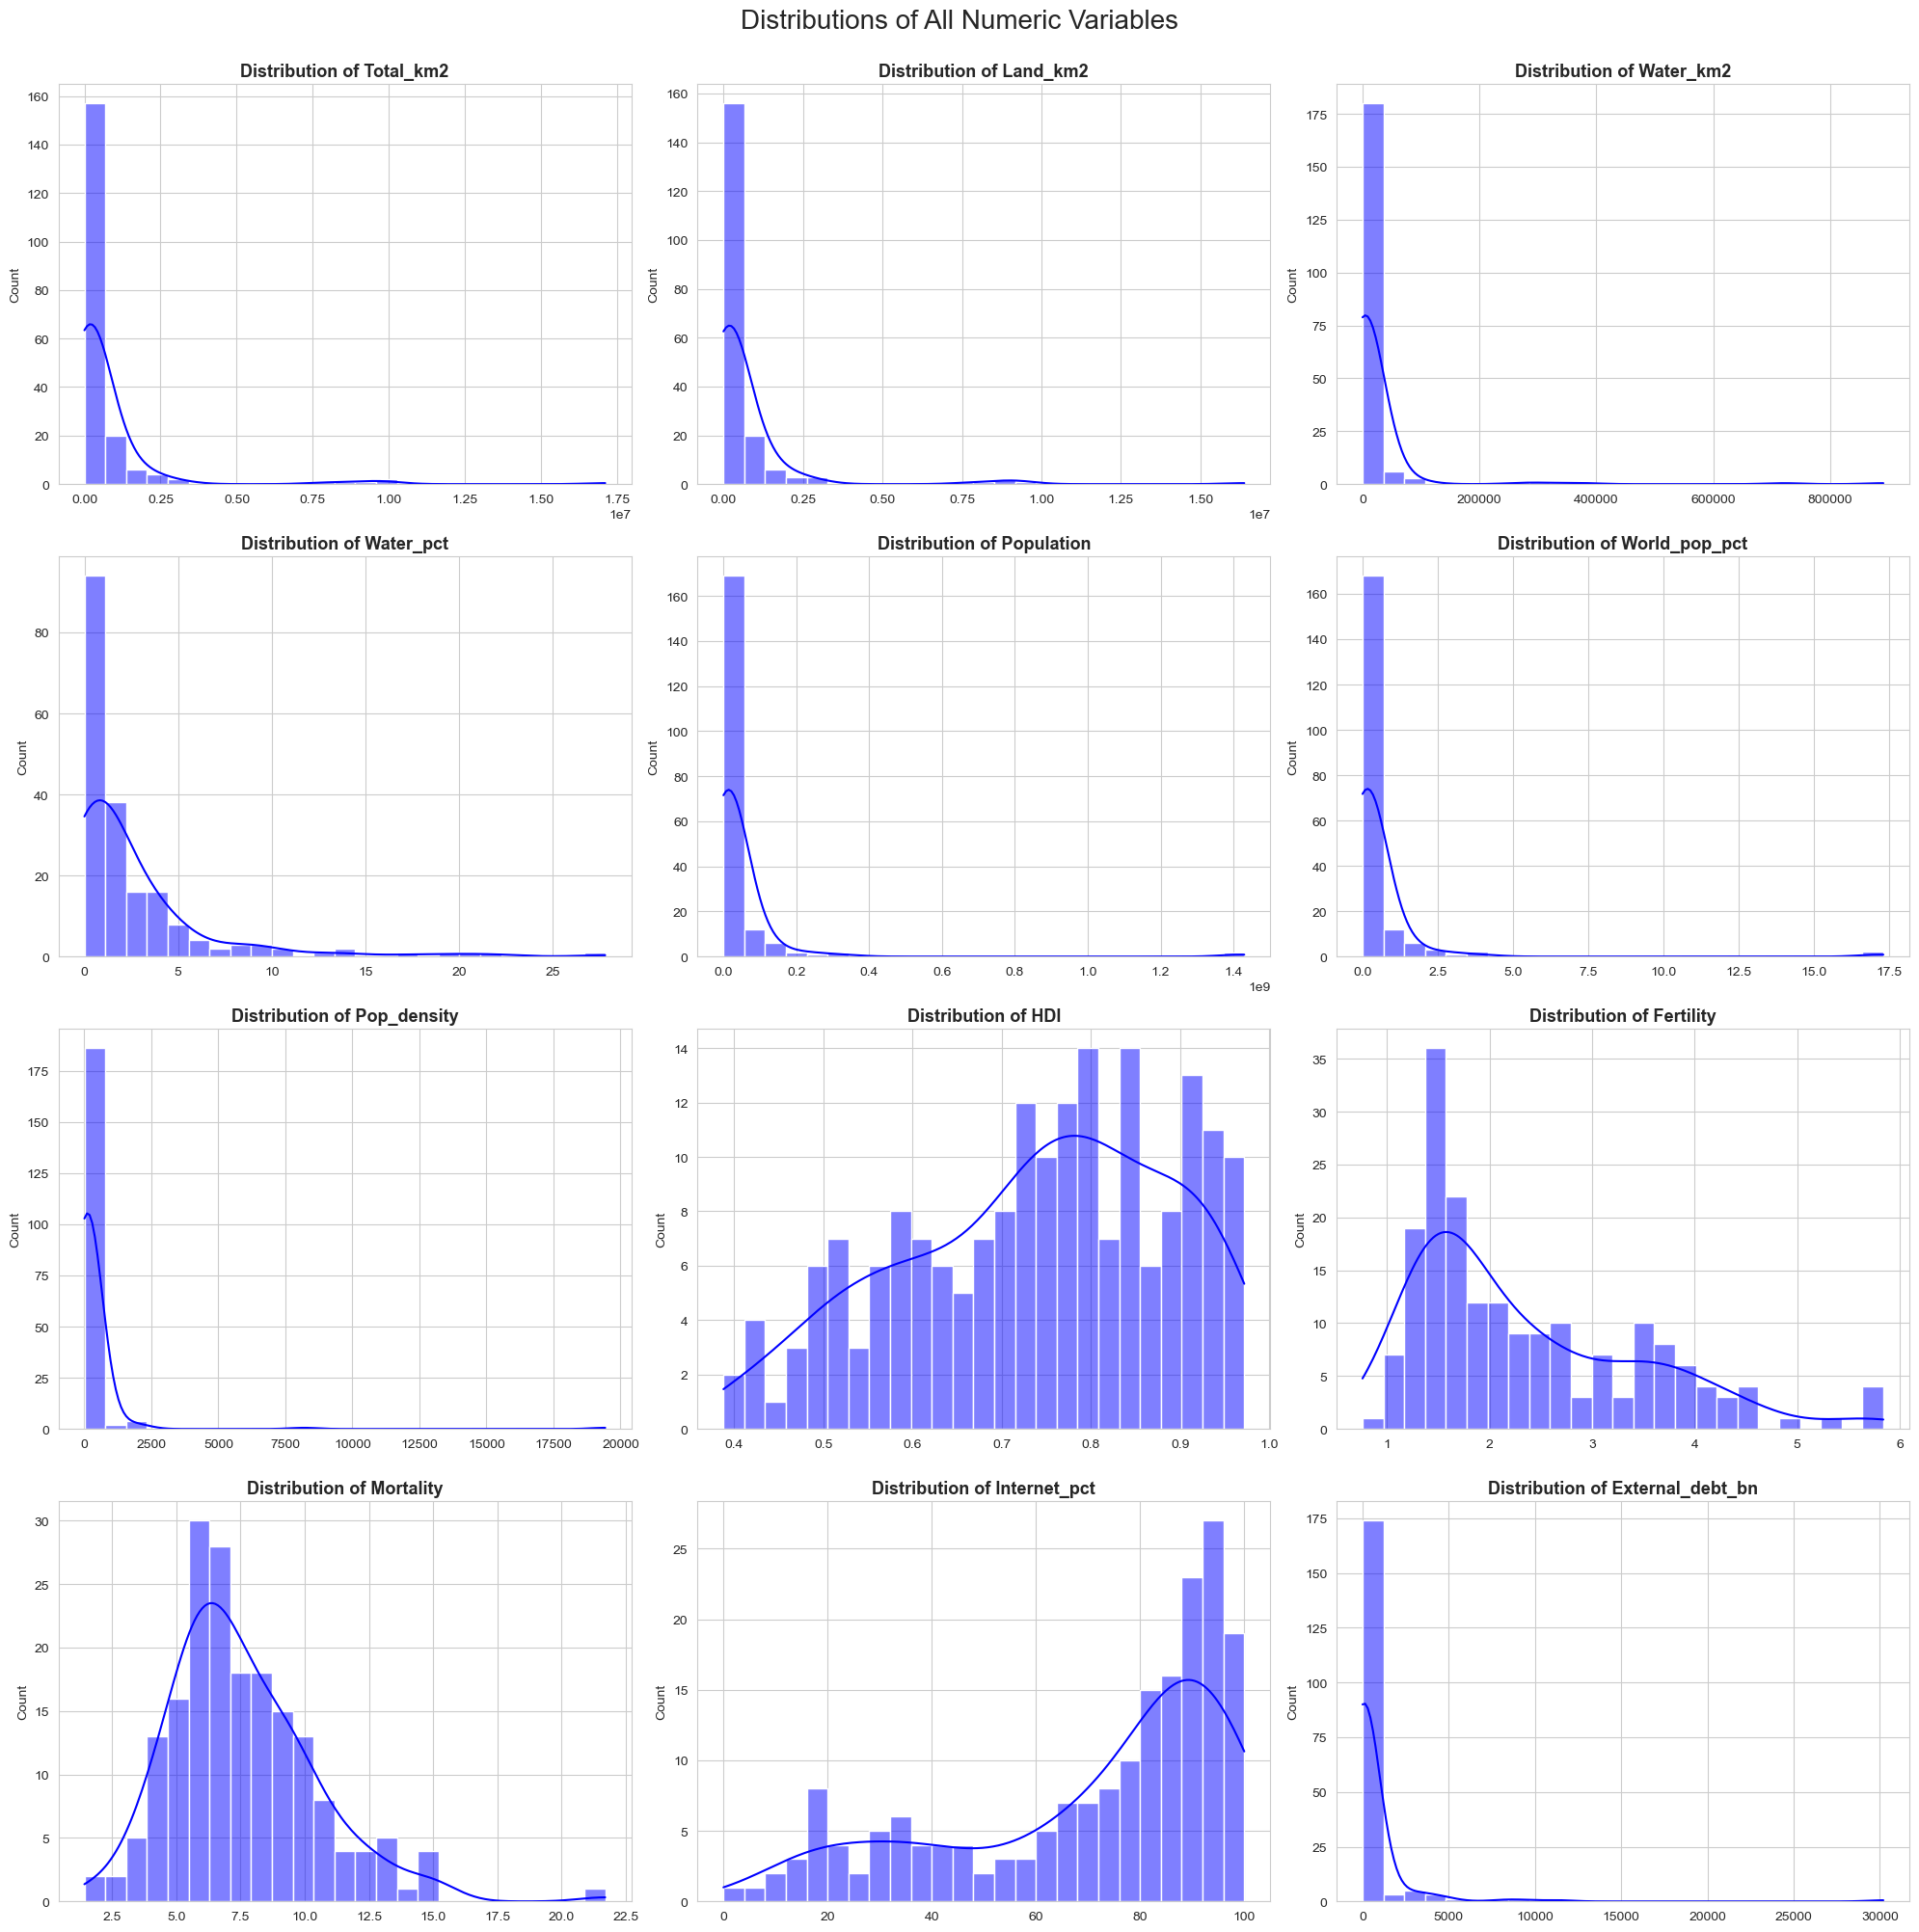

In [20]:
cols_to_plot = ['Total_km2', 'Land_km2', 'Water_km2', 'Water_pct',
                'Population', 'World_pop_pct', 'Pop_density', 'HDI',
                'Fertility', 'Mortality', 'Internet_pct', 'External_debt_bn']

fig, axes = plt.subplots(4, 3, figsize=(20, 20))
axes = axes.flatten()
for i, col in enumerate(cols_to_plot):
    sns.histplot(df[col].dropna(), kde=True, bins=25, ax=axes[i], color='b')
    axes[i].set_title(f'Distribution of {col}')
    axes[i].set_xlabel('')
plt.suptitle('Distributions of All Numeric Variables', fontsize=20, y=1)
plt.tight_layout()
plt.show()

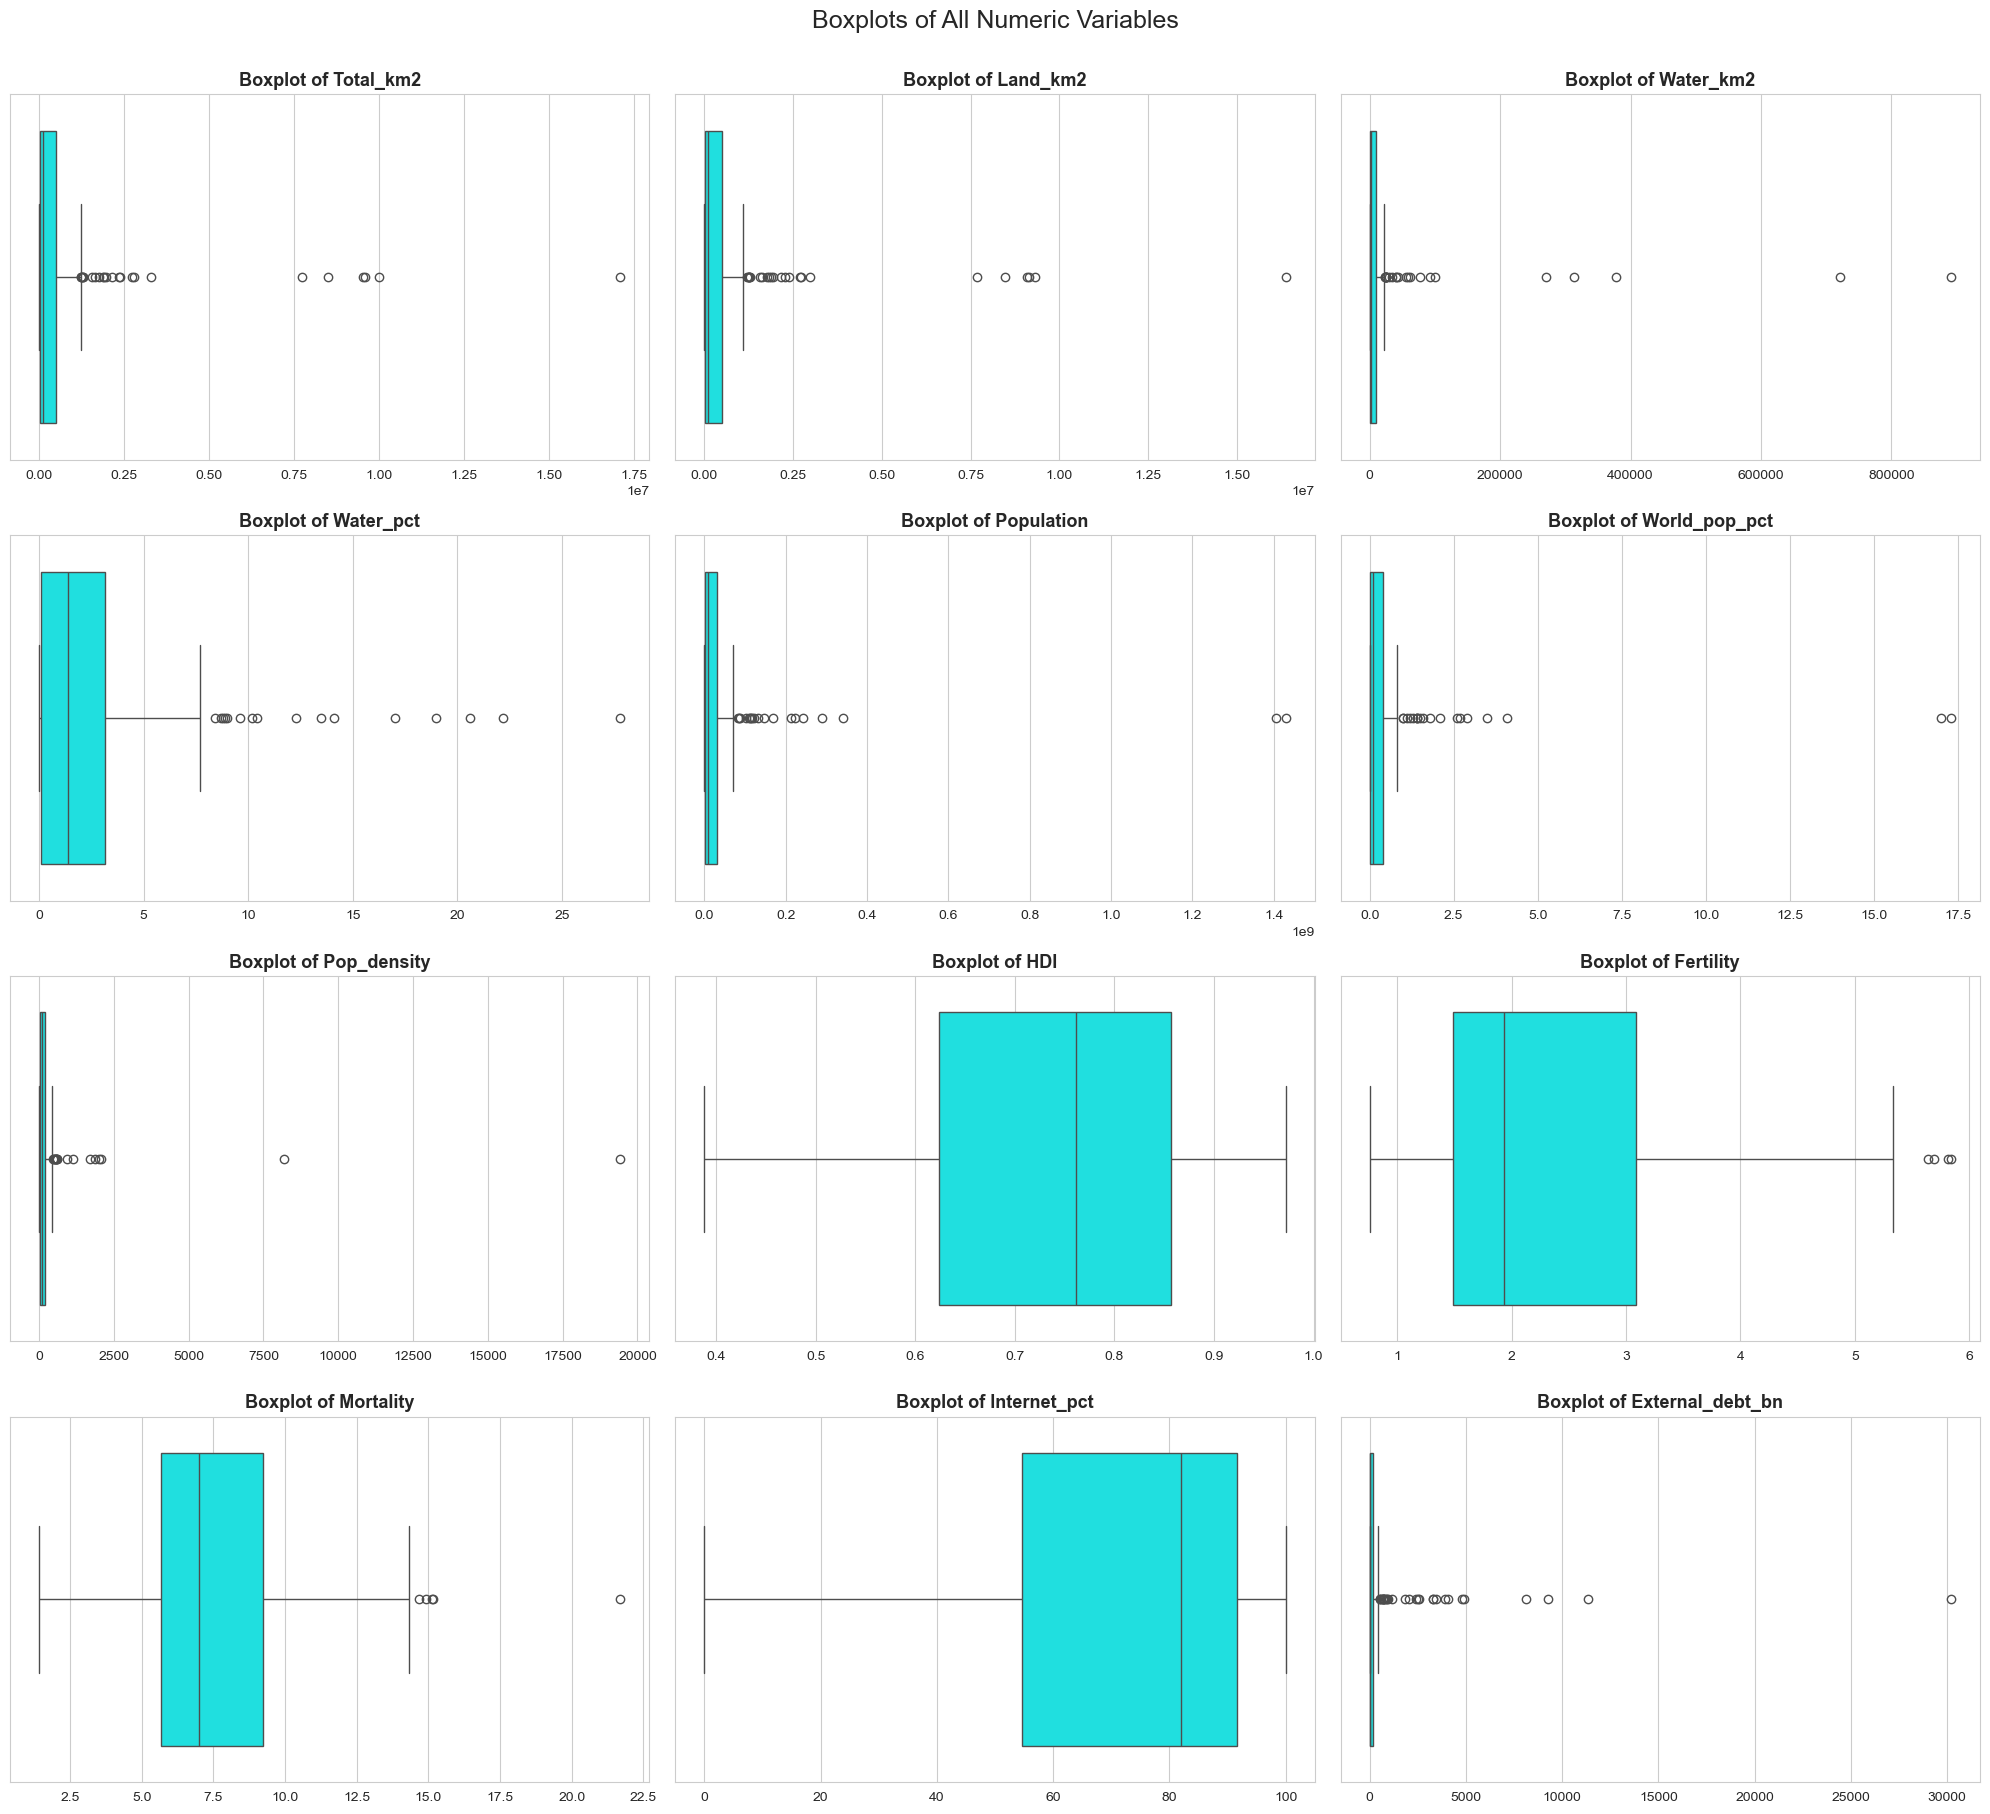

In [21]:
fig, axes = plt.subplots(4, 3, figsize=(20, 18))
axes = axes.flatten()
for i, col in enumerate(cols_to_plot):
    sns.boxplot(x=df[col].dropna(), ax=axes[i], color='cyan')
    axes[i].set_title(f'Boxplot of {col}')
    axes[i].set_xlabel('')
plt.suptitle('Boxplots of All Numeric Variables', fontsize=18, y=1.005)
plt.tight_layout()
plt.show()

In [22]:
num_df = df.select_dtypes(include=[np.number])
corr = num_df.corr()

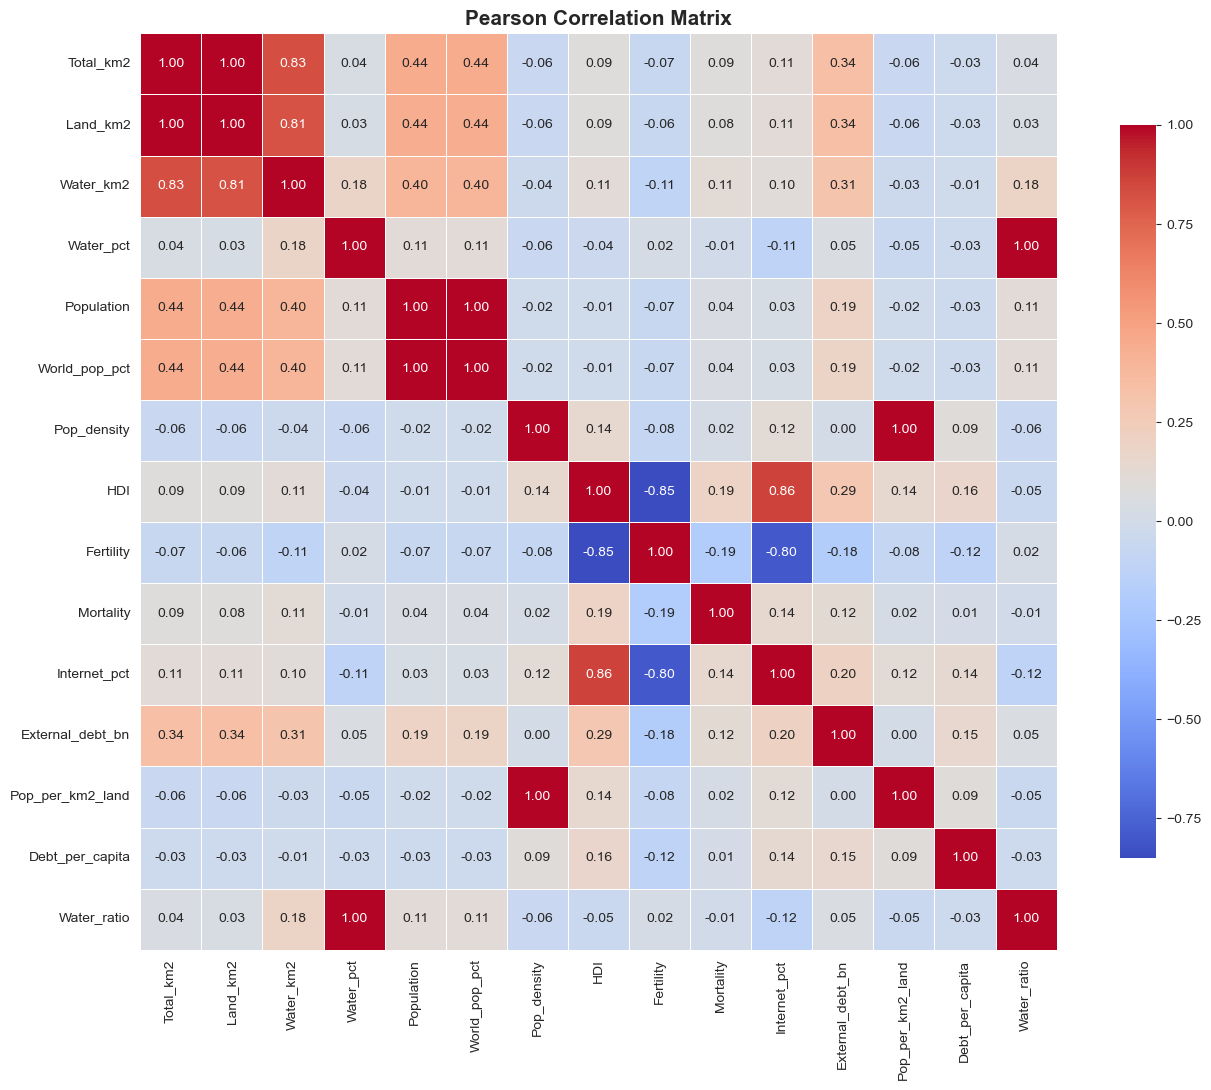

In [23]:
plt.figure(figsize=(14, 11))
sns.heatmap(corr, annot=True, cmap='coolwarm', fmt='.2f',
            linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Pearson Correlation Matrix', fontsize=15)
plt.tight_layout()
plt.show()

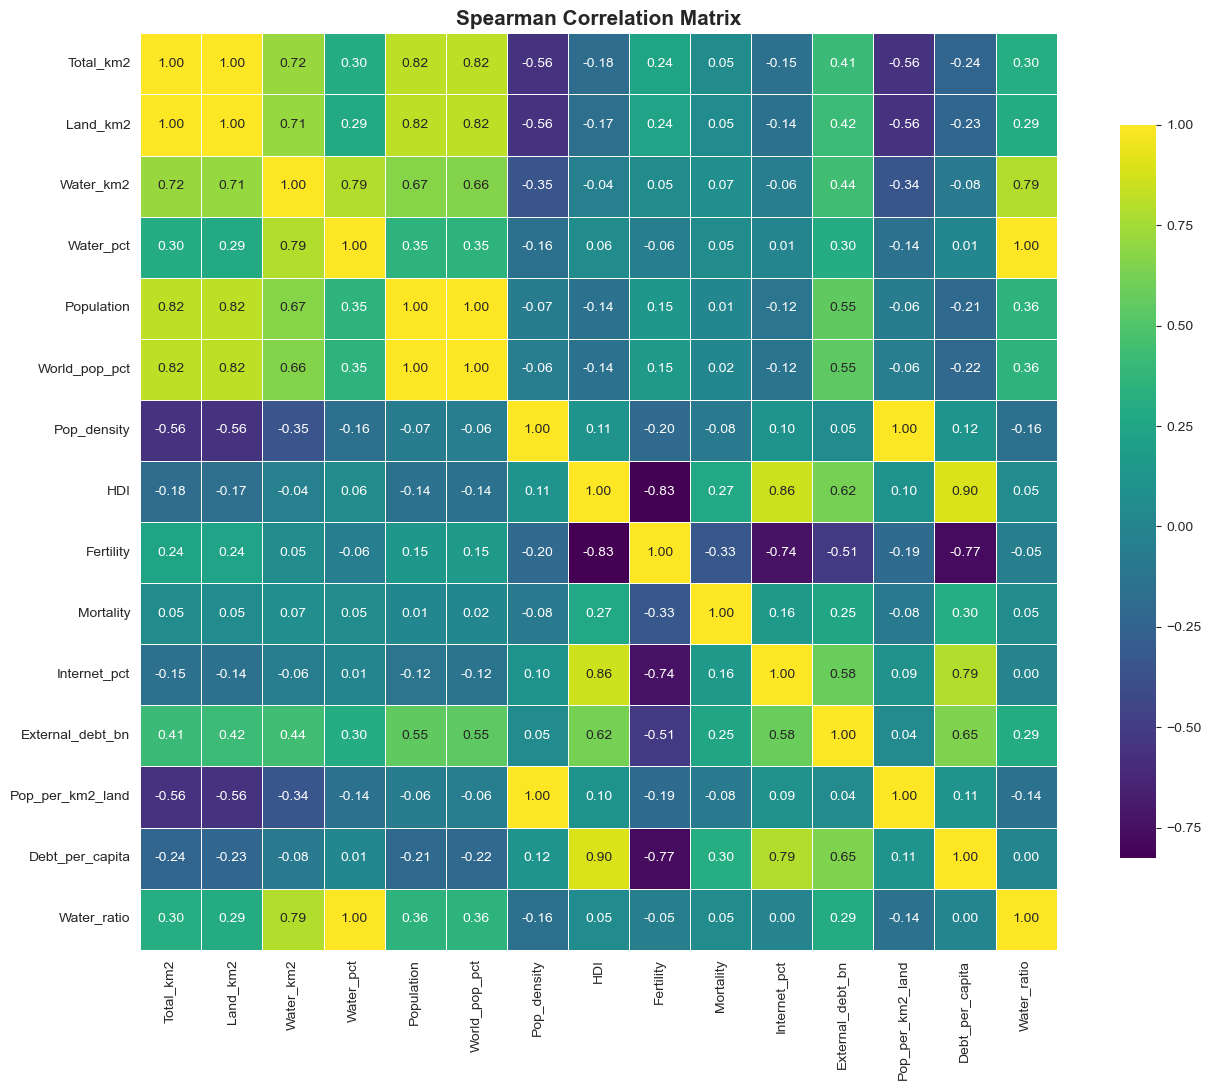

In [24]:
plt.figure(figsize=(14, 11))
sns.heatmap(num_df.corr(method='spearman'), annot=True, cmap='viridis',
            fmt='.2f', linewidths=0.5, square=True, cbar_kws={'shrink': 0.8})
plt.title('Spearman Correlation Matrix', fontsize=15)
plt.tight_layout()
plt.show()

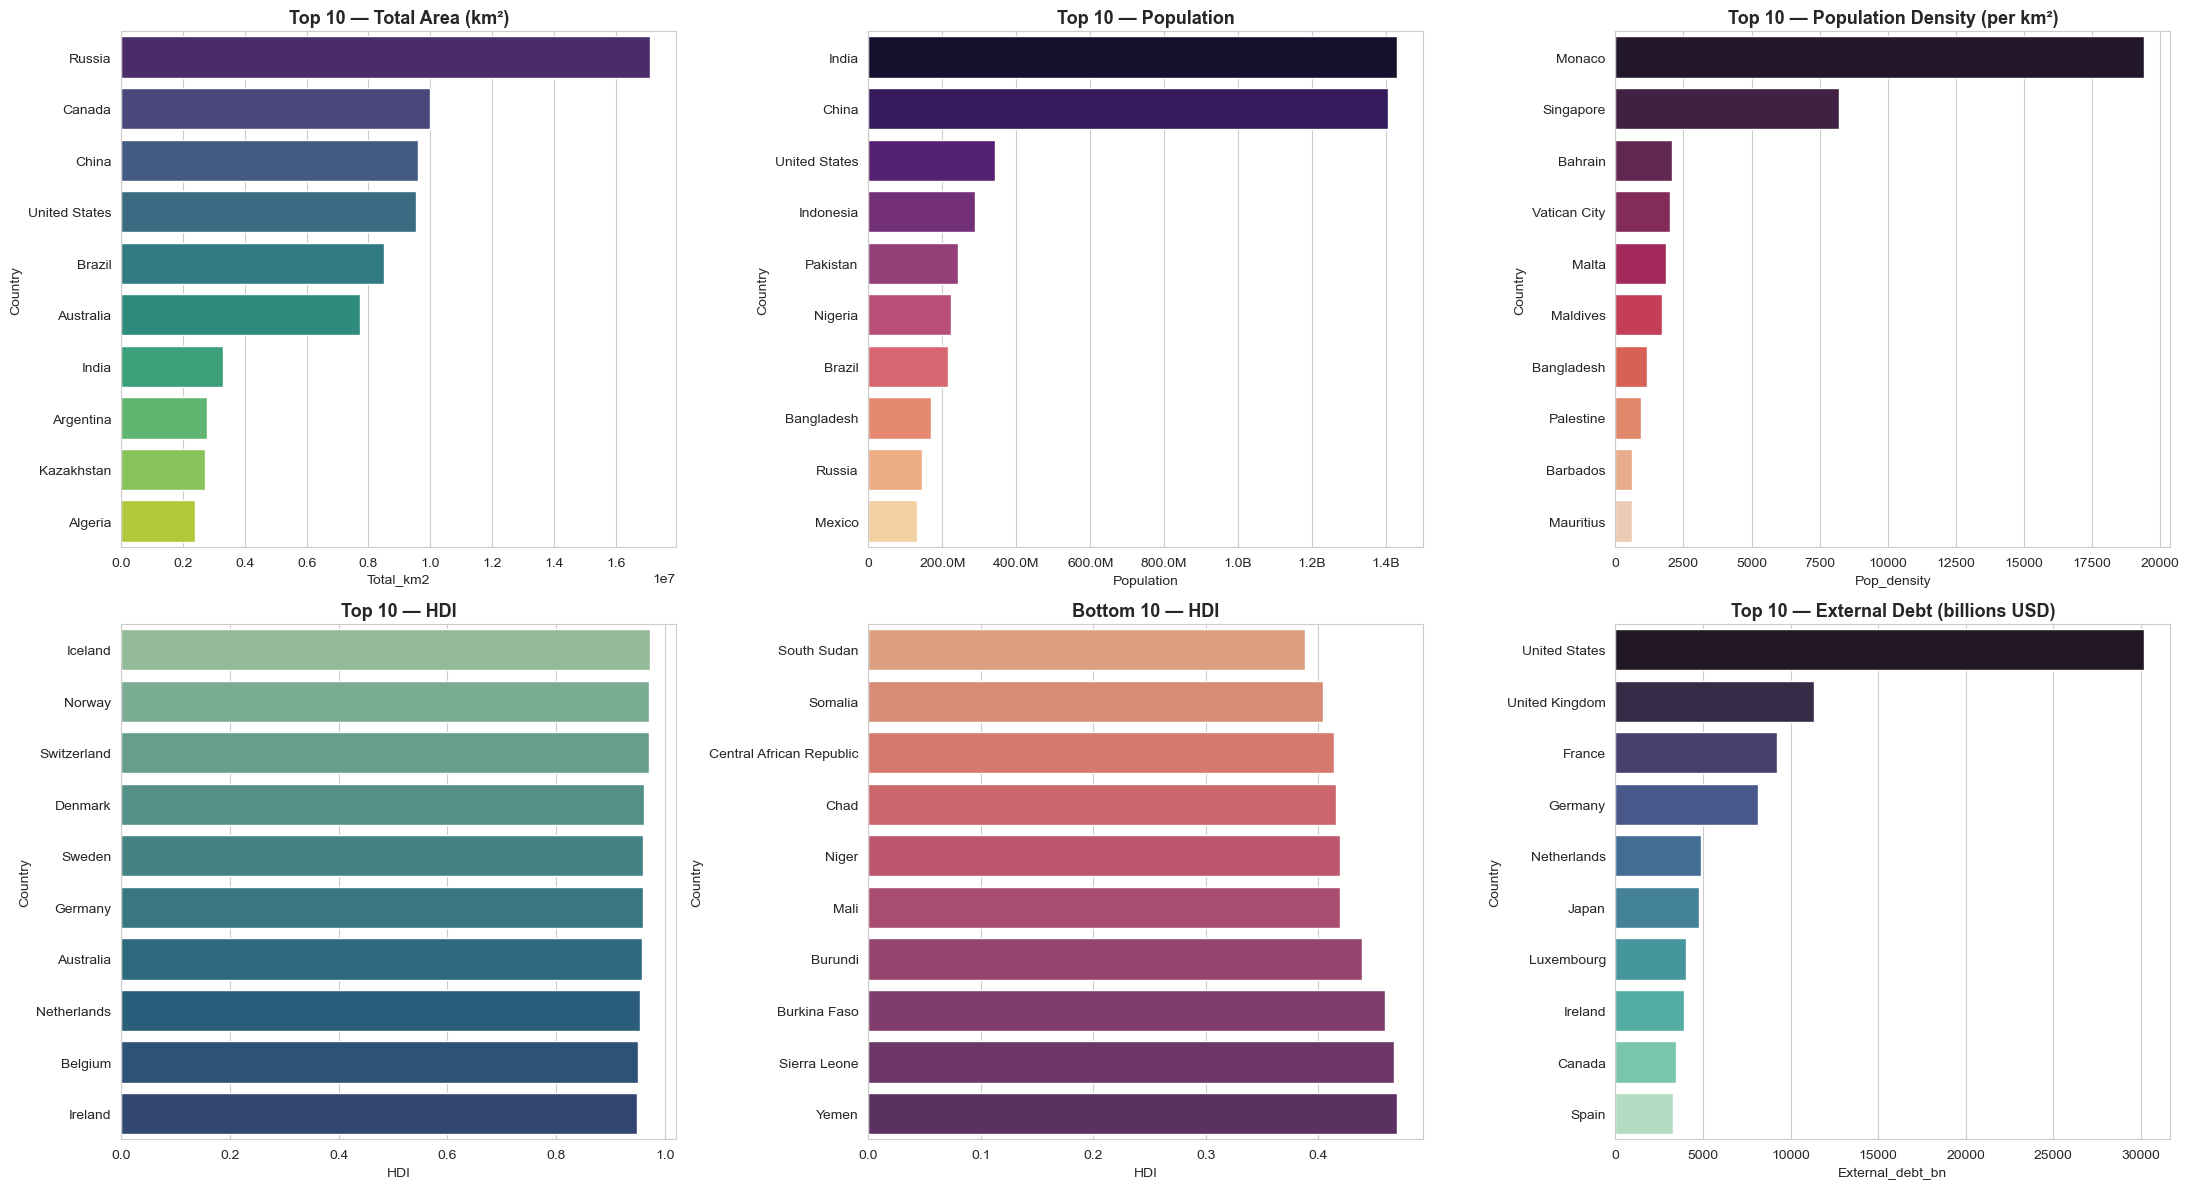

In [29]:
fig, axes = plt.subplots(2, 3, figsize=(22, 12))

sns.barplot(data=top_area, y='Country', x='Total_km2', ax=axes[0,0], palette='viridis')
axes[0,0].set_title('Top 10 — Total Area (km²)')

sns.barplot(data=top_pop, y='Country', x='Population', ax=axes[0,1], palette='magma')
axes[0,1].set_title('Top 10 — Population')
axes[0,1].xaxis.set_major_formatter(FuncFormatter(human_format))

sns.barplot(data=top_dens, y='Country', x='Pop_density', ax=axes[0,2], palette='rocket')
axes[0,2].set_title('Top 10 — Population Density (per km²)')

sns.barplot(data=top_hdi, y='Country', x='HDI', ax=axes[1,0], palette='crest')
axes[1,0].set_title('Top 10 — HDI')

sns.barplot(data=bot_hdi, y='Country', x='HDI', ax=axes[1,1], palette='flare')
axes[1,1].set_title('Bottom 10 — HDI')

sns.barplot(data=top_debt, y='Country', x='External_debt_bn', ax=axes[1,2], palette='mako')
axes[1,2].set_title('Top 10 — External Debt (billions USD)')

plt.tight_layout()
plt.show()

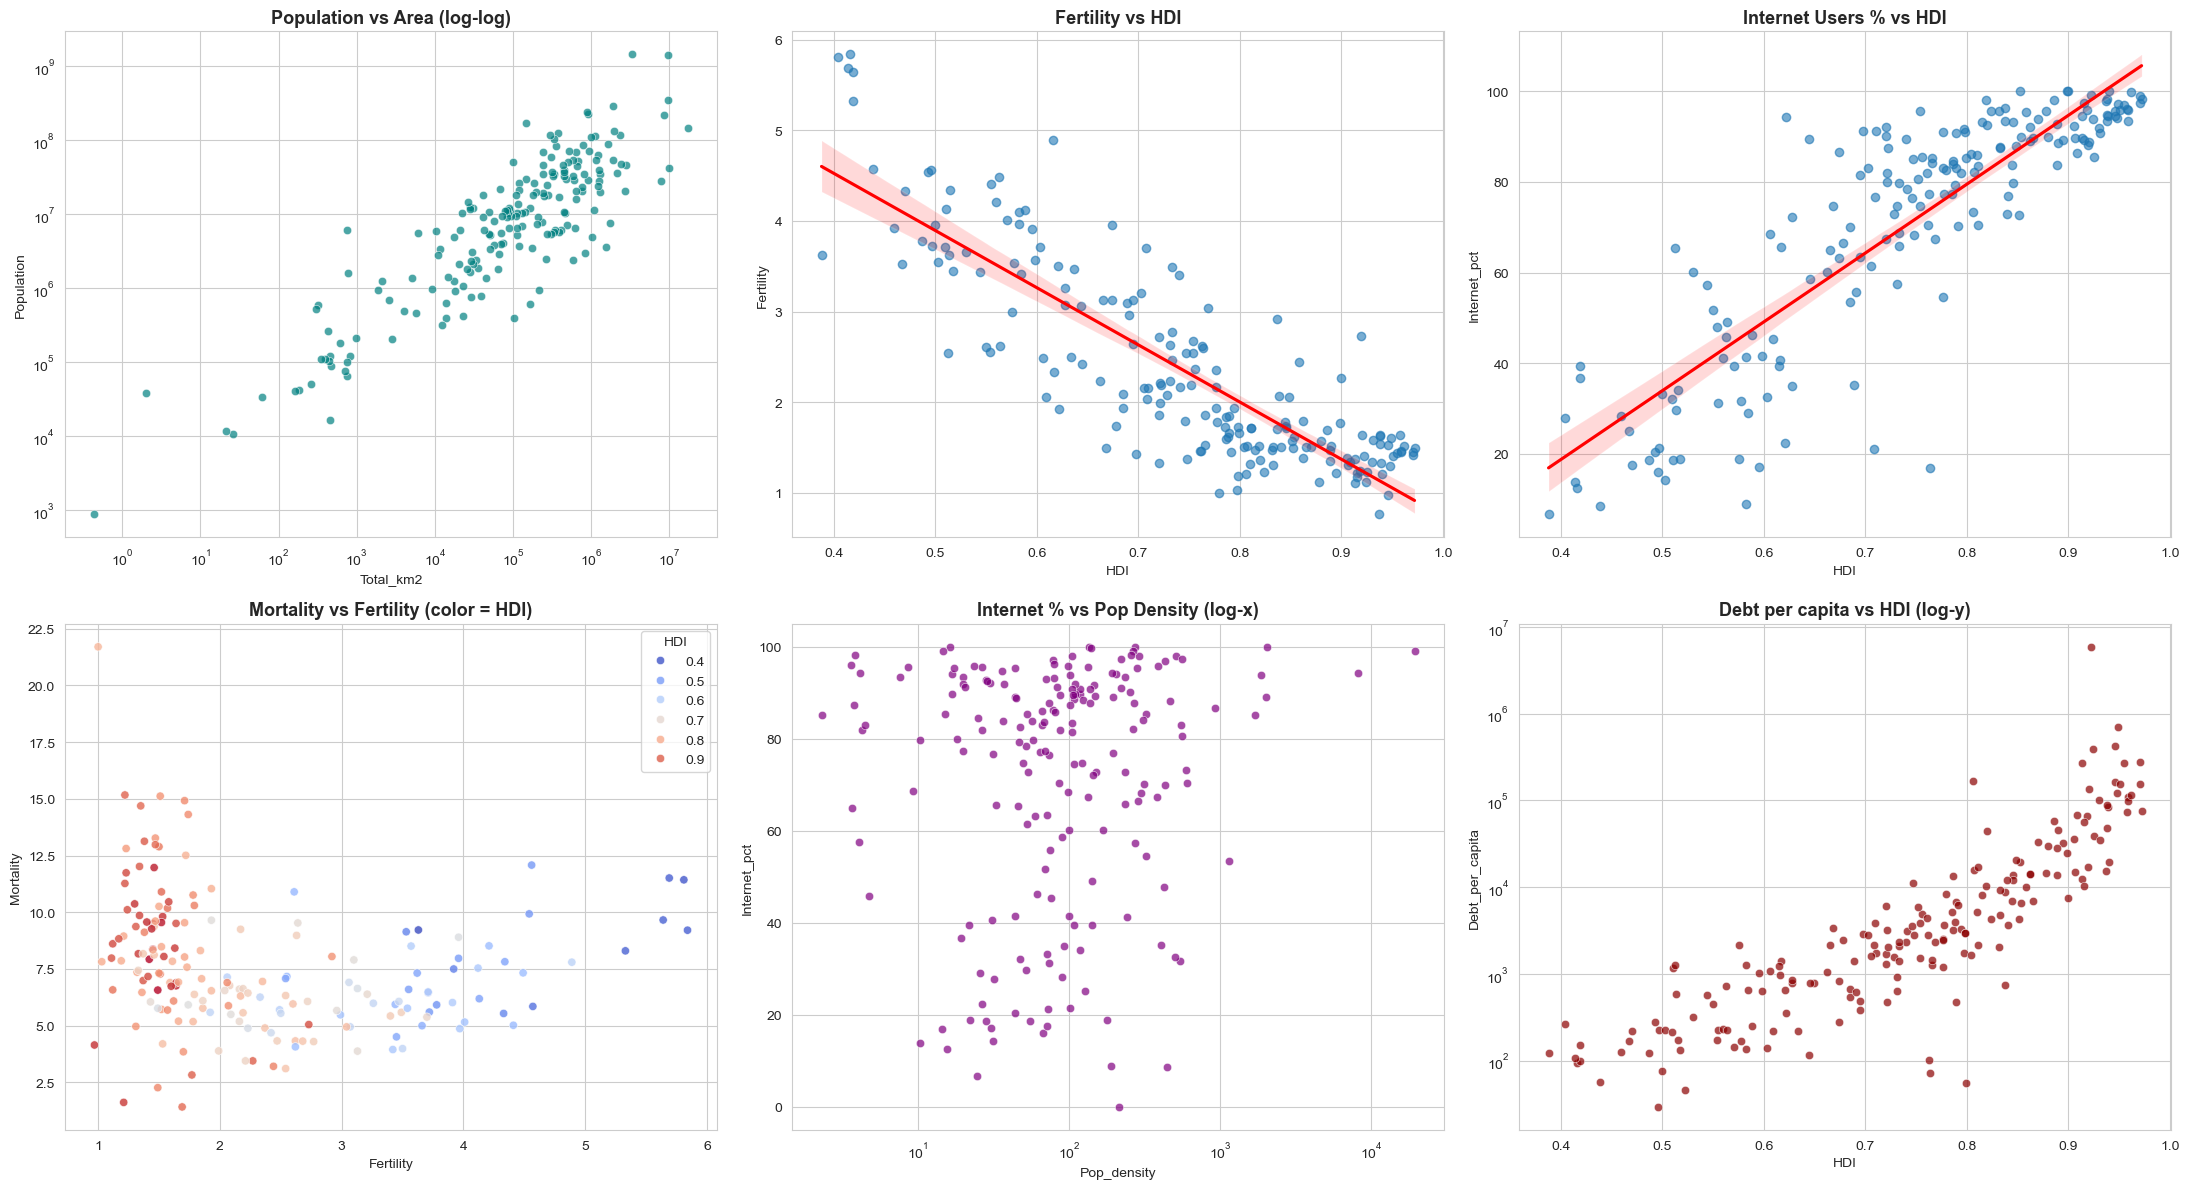

In [31]:
fig, axes = plt.subplots(2, 3, figsize=(22, 12))

# 7.1 Population vs Area (log-log)
sns.scatterplot(data=df, x='Total_km2', y='Population', ax=axes[0,0], alpha=0.7, color='teal')
axes[0,0].set_xscale('log'); axes[0,0].set_yscale('log')
axes[0,0].set_title('Population vs Area (log-log)')

# 7.2 HDI vs Fertility
sns.regplot(data=df, x='HDI', y='Fertility', ax=axes[0,1],scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[0,1].set_title('Fertility vs HDI')

# 7.3 Internet vs HDI
sns.regplot(data=df, x='HDI', y='Internet_pct', ax=axes[0,2], scatter_kws={'alpha':0.6}, line_kws={'color':'red'})
axes[0,2].set_title('Internet Users % vs HDI')

# 7.4 Mortality vs Fertility
sns.scatterplot(data=df, x='Fertility', y='Mortality', hue='HDI',palette='coolwarm', ax=axes[1,0], alpha=0.8)
axes[1,0].set_title('Mortality vs Fertility (color = HDI)')

# 7.5 Pop density vs Internet %
sns.scatterplot(data=df, x='Pop_density', y='Internet_pct', ax=axes[1,1],alpha=0.7, color='purple')
axes[1,1].set_xscale('log')
axes[1,1].set_title('Internet % vs Pop Density (log-x)')

# 7.6 Debt per capita vs HDI
sns.scatterplot(data=df, x='HDI', y='Debt_per_capita', ax=axes[1,2],alpha=0.7, color='darkred')
axes[1,2].set_yscale('log')
axes[1,2].set_title('Debt per capita vs HDI (log-y)')

plt.tight_layout()
plt.show()



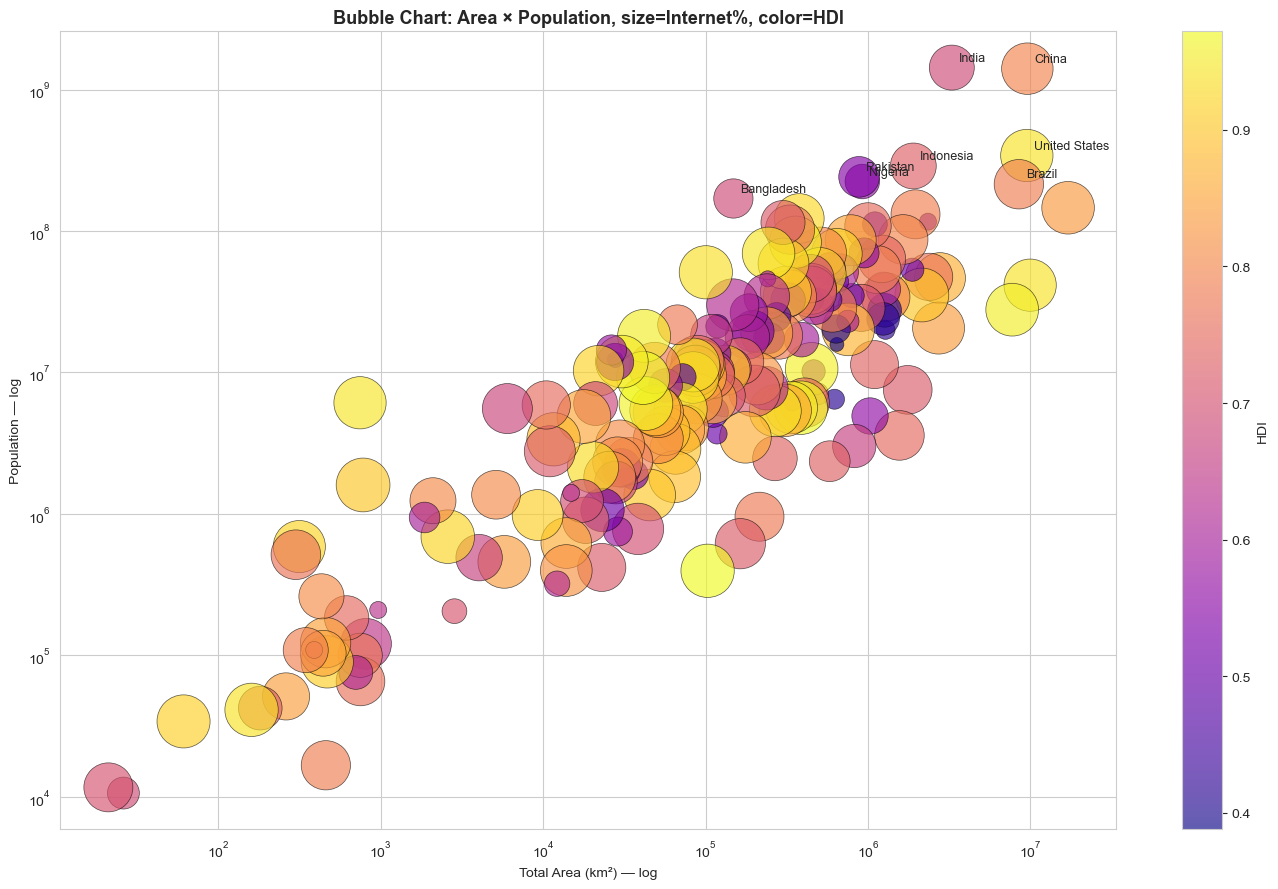

In [34]:
fig, ax = plt.subplots(figsize=(14, 9))
sizes = (df['Internet_pct'].fillna(10)) * 15
sc = ax.scatter(
    df['Total_km2'], df['Population'],
    s=sizes, c=df['HDI'], cmap='plasma',
    alpha=0.65, edgecolor='k', linewidth=0.5
)
ax.set_xscale('log'); ax.set_yscale('log')
ax.set_xlabel('Total Area (km²) — log'); ax.set_ylabel('Population — log')
ax.set_title('Bubble Chart: Area × Population, size=Internet%, color=HDI')

# Annotate the biggest points
for _, r in df.nlargest(8, 'Population').iterrows():
    ax.annotate(r['Country'], (r['Total_km2'], r['Population']),
                fontsize=9, xytext=(5, 5), textcoords='offset points')
plt.colorbar(sc, label='HDI')
plt.tight_layout()
plt.show()

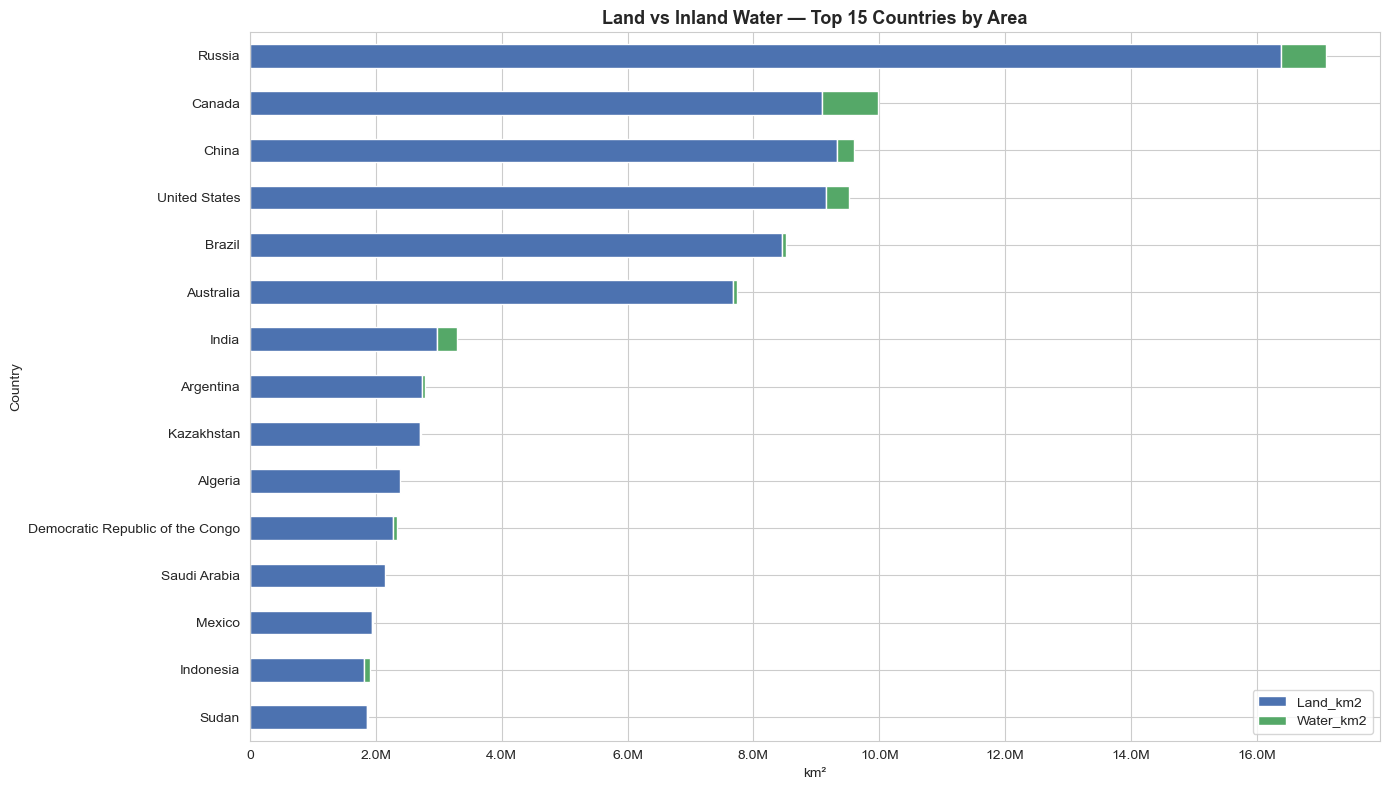

In [35]:
top15 = df.nlargest(15, 'Total_km2')[['Country','Land_km2','Water_km2']].set_index('Country')
fig, ax = plt.subplots(figsize=(14, 8))
top15[['Land_km2','Water_km2']].plot(kind='barh', stacked=True,
                                     color=['#4c72b0','#55a868'], ax=ax)
ax.set_xlabel('km²')
ax.set_title('Land vs Inland Water — Top 15 Countries by Area')
ax.xaxis.set_major_formatter(FuncFormatter(human_format))
ax.invert_yaxis()
plt.tight_layout()
plt.show()

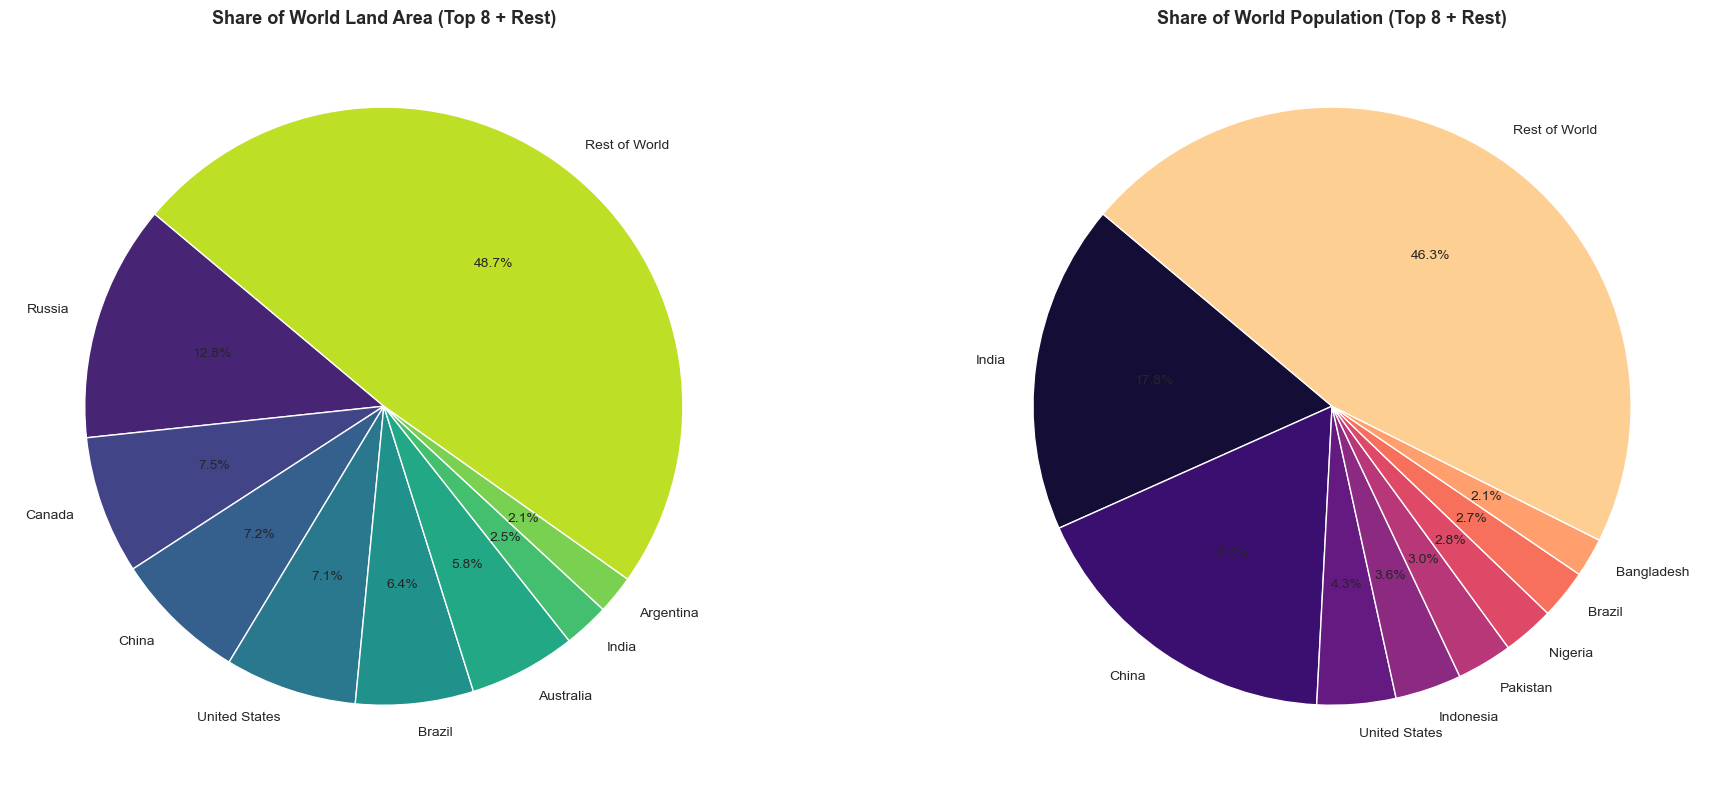

In [36]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8))

area_share = df.nlargest(8, 'Total_km2').set_index('Country')['Total_km2']
area_share['Rest of World'] = df['Total_km2'].sum() - area_share.sum()
axes[0].pie(area_share, labels=area_share.index, autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('viridis', len(area_share)))
axes[0].set_title('Share of World Land Area (Top 8 + Rest)')

pop_share = df.nlargest(8, 'Population').set_index('Country')['Population']
pop_share['Rest of World'] = df['Population'].sum() - pop_share.sum()
axes[1].pie(pop_share, labels=pop_share.index, autopct='%1.1f%%',
            startangle=140, colors=sns.color_palette('magma', len(pop_share)))
axes[1].set_title('Share of World Population (Top 8 + Rest)')

plt.tight_layout()
plt.show()

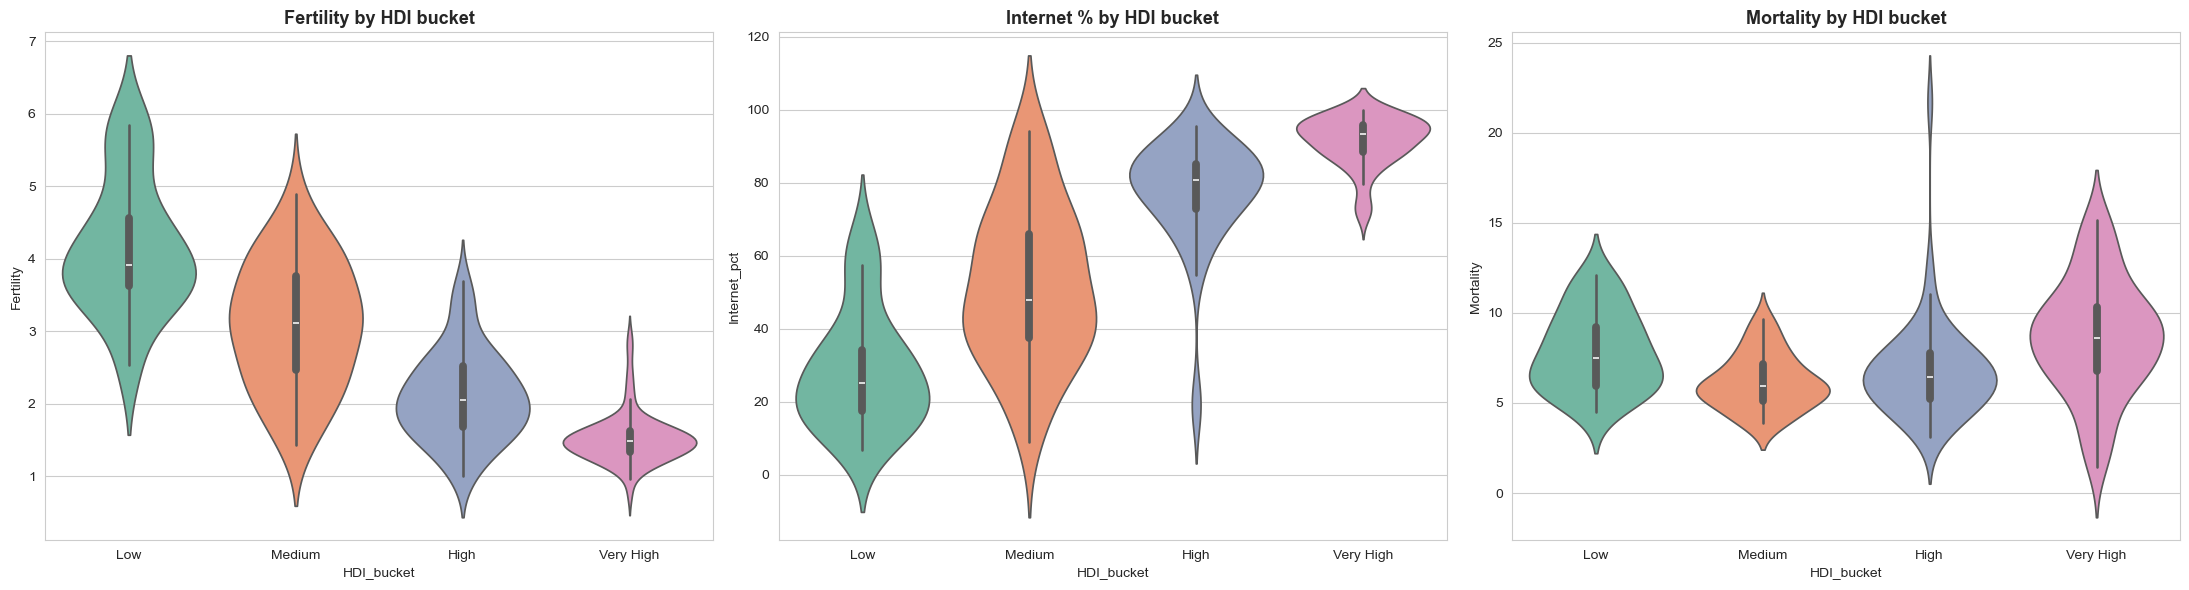

In [39]:
df['HDI_bucket'] = pd.cut(df['HDI'],
                          bins=[0, 0.55, 0.70, 0.80, 1.0],
                          labels=['Low','Medium','High','Very High'])

fig, axes = plt.subplots(1, 3, figsize=(22, 6))
sns.violinplot(data=df, x='HDI_bucket', y='Fertility', ax=axes[0], palette='Set2', inner='box')
axes[0].set_title('Fertility by HDI bucket')

sns.violinplot(data=df, x='HDI_bucket', y='Internet_pct', ax=axes[1], palette='Set2', inner='box')
axes[1].set_title('Internet % by HDI bucket')

sns.violinplot(data=df, x='HDI_bucket', y='Mortality', ax=axes[2], palette='Set2', inner='box')
axes[2].set_title('Mortality by HDI bucket')
plt.tight_layout()
plt.show()

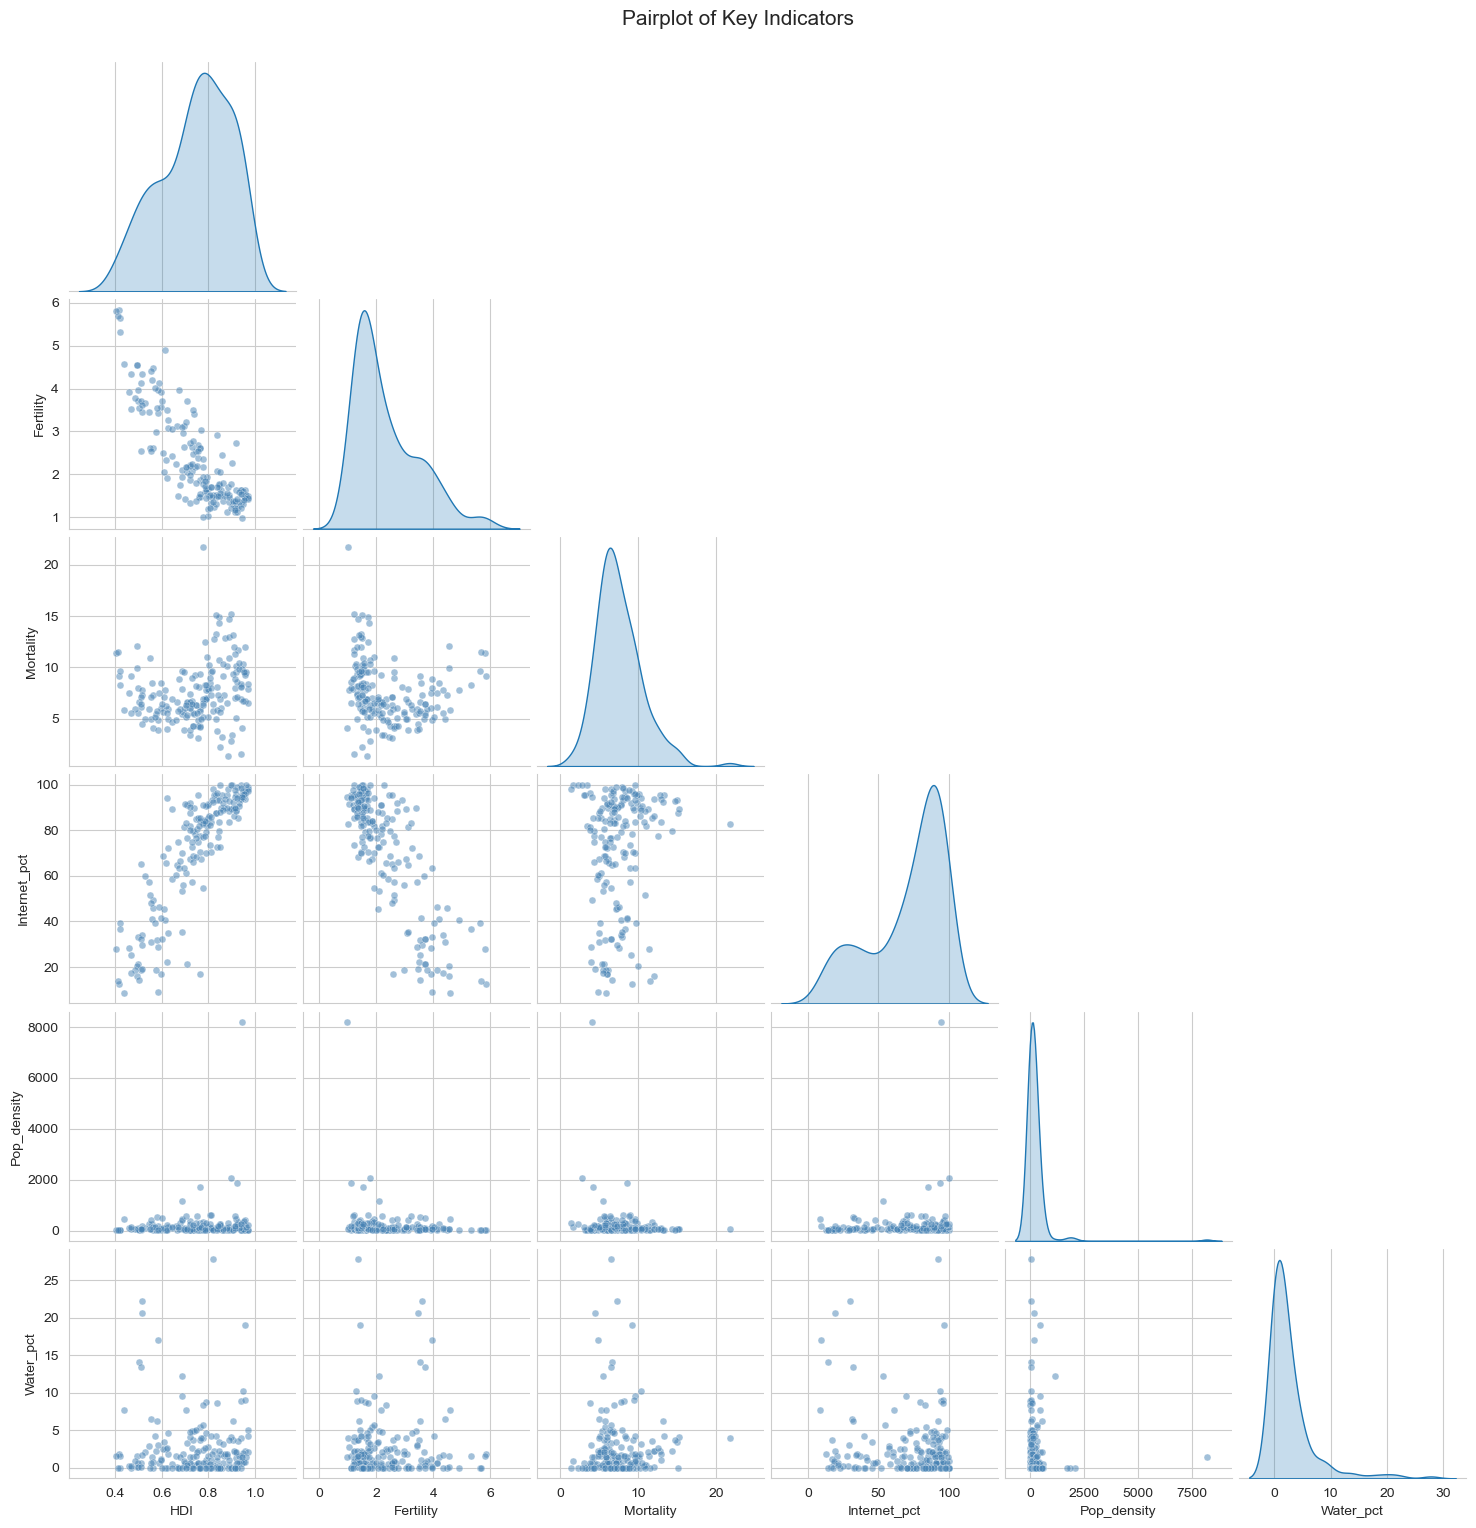

In [41]:
subset = ['HDI','Fertility','Mortality','Internet_pct','Pop_density','Water_pct']
g = sns.pairplot(df[subset].dropna(), diag_kind='kde',
                 plot_kws={'alpha':0.5, 's':25, 'color':'steelblue'},
                 corner=True)
g.fig.suptitle('Pairplot of Key Indicators', y=1.02, fontsize=15)
plt.show()

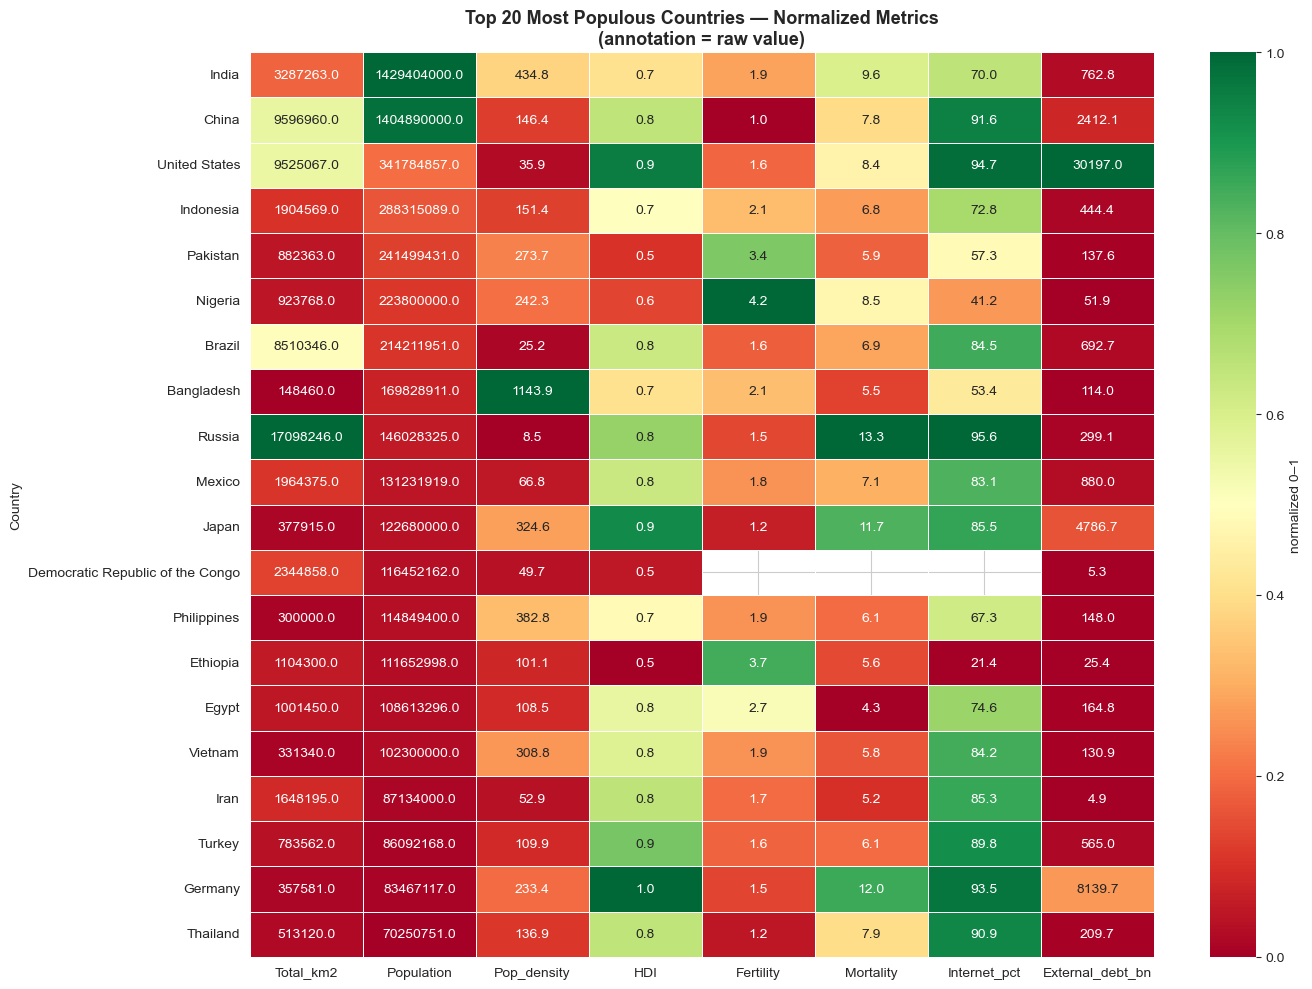

In [42]:
metrics = ['Total_km2','Population','Pop_density','HDI',
           'Fertility','Mortality','Internet_pct','External_debt_bn']
top20 = df.nlargest(20, 'Population').set_index('Country')[metrics]

norm = (top20 - top20.min()) / (top20.max() - top20.min())

plt.figure(figsize=(14, 10))
sns.heatmap(norm, cmap='RdYlGn', annot=top20.round(1), fmt='',
            linewidths=0.5, cbar_kws={'label':'normalized 0–1'})
plt.title('Top 20 Most Populous Countries — Normalized Metrics\n(annotation = raw value)')
plt.tight_layout()
plt.show()


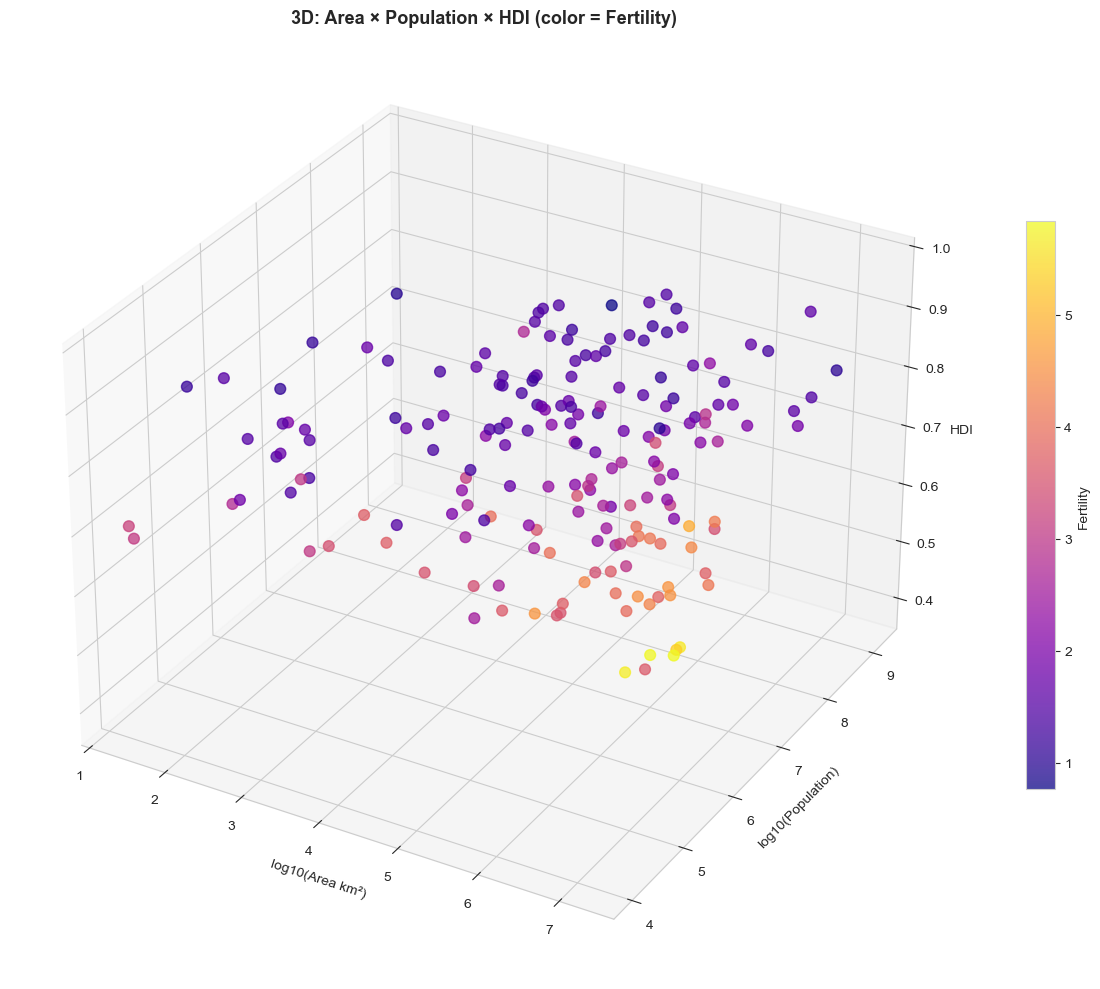

In [43]:
fig = plt.figure(figsize=(14, 10))
ax = fig.add_subplot(111, projection='3d')
sc = ax.scatter(
    np.log10(df['Total_km2']),
    np.log10(df['Population']),
    df['HDI'],
    c=df['Fertility'], cmap='plasma', s=60, alpha=0.75
)
ax.set_xlabel('log10(Area km²)')
ax.set_ylabel('log10(Population)')
ax.set_zlabel('HDI')
ax.set_title('3D: Area × Population × HDI (color = Fertility)')
plt.colorbar(sc, shrink=0.6, label='Fertility')
plt.tight_layout()
plt.show()

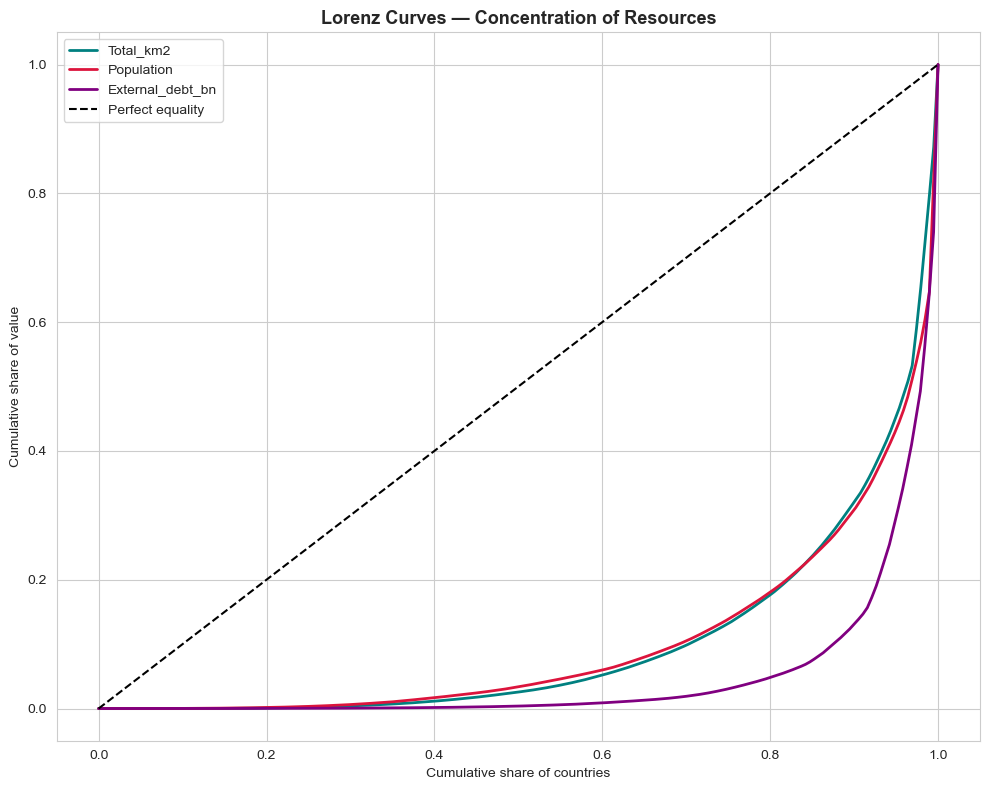

In [44]:
def lorenz(values):
    v = np.sort(values.dropna().values)
    cum = np.cumsum(v) / v.sum()
    x = np.arange(1, len(v)+1) / len(v)
    return np.insert(x, 0, 0), np.insert(cum, 0, 0)

fig, ax = plt.subplots(figsize=(10, 8))
for col, color in zip(['Total_km2','Population','External_debt_bn'],
                      ['teal','crimson','purple']):
    x, y = lorenz(df[col])
    ax.plot(x, y, label=f'{col}', color=color, linewidth=2)
ax.plot([0,1],[0,1],'k--',label='Perfect equality')
ax.set_xlabel('Cumulative share of countries')
ax.set_ylabel('Cumulative share of value')
ax.set_title('Lorenz Curves — Concentration of Resources')
ax.legend()
plt.tight_layout()
plt.show()

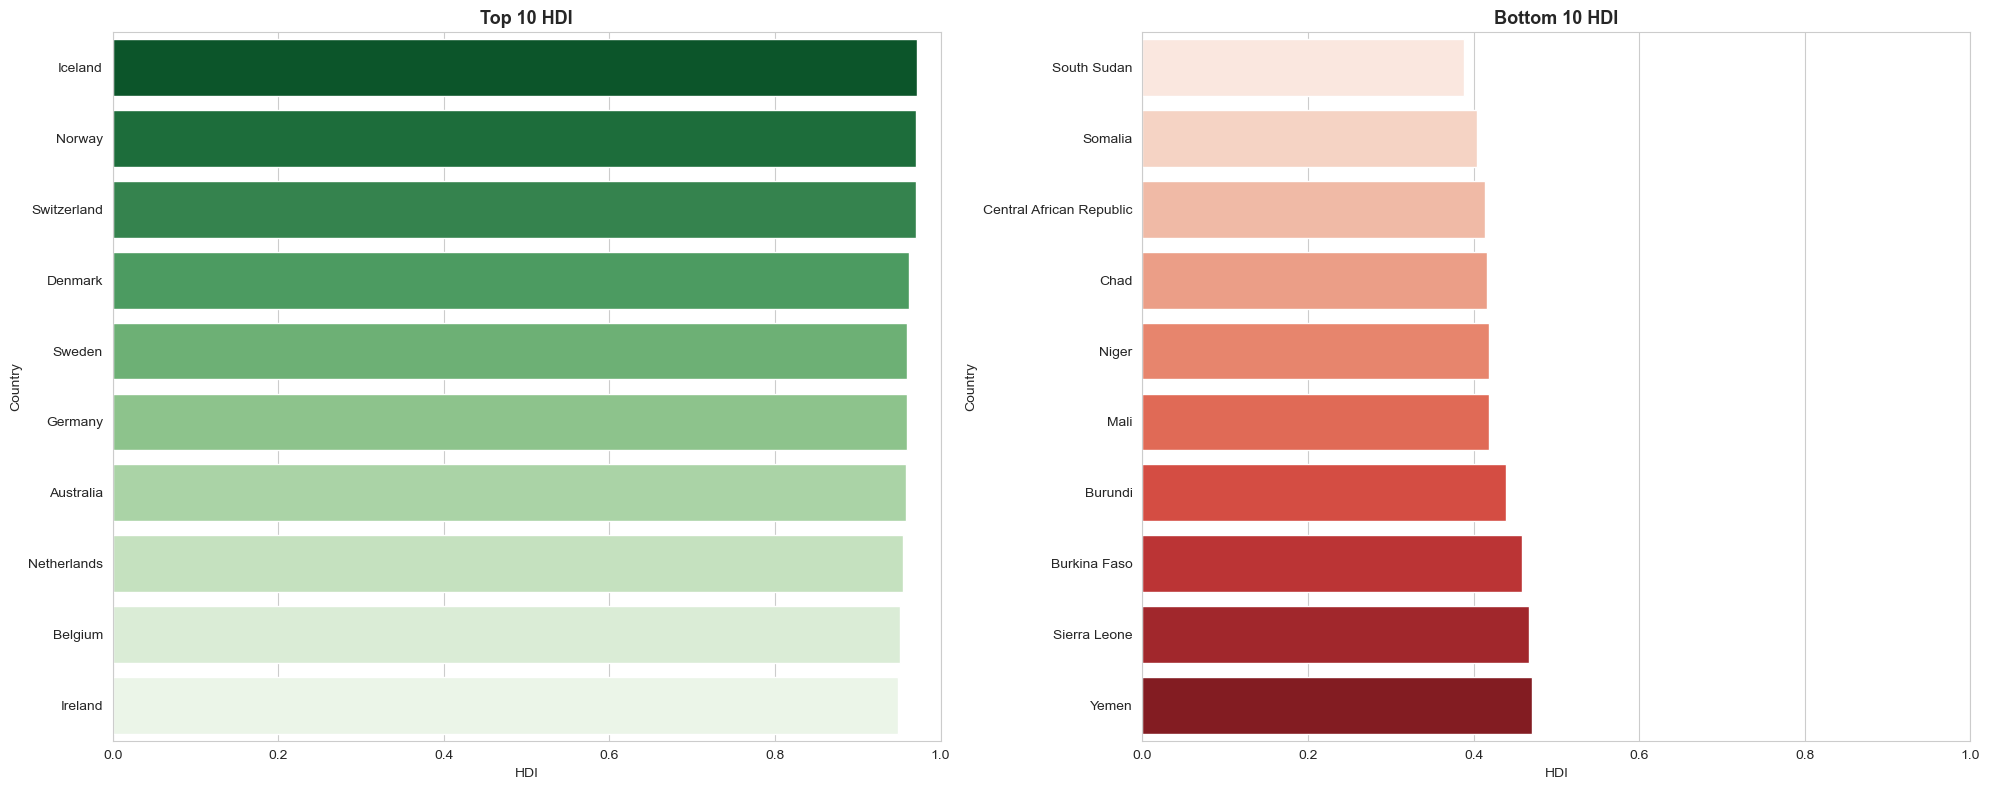

In [45]:
fig, axes = plt.subplots(1, 2, figsize=(20, 8), sharex=True)
sns.barplot(data=top_hdi, y='Country', x='HDI', ax=axes[0], palette='Greens_r')
axes[0].set_title('Top 10 HDI'); axes[0].set_xlim(0, 1)
sns.barplot(data=bot_hdi, y='Country', x='HDI', ax=axes[1], palette='Reds')
axes[1].set_title('Bottom 10 HDI'); axes[1].set_xlim(0, 1)
plt.tight_layout()
plt.show()

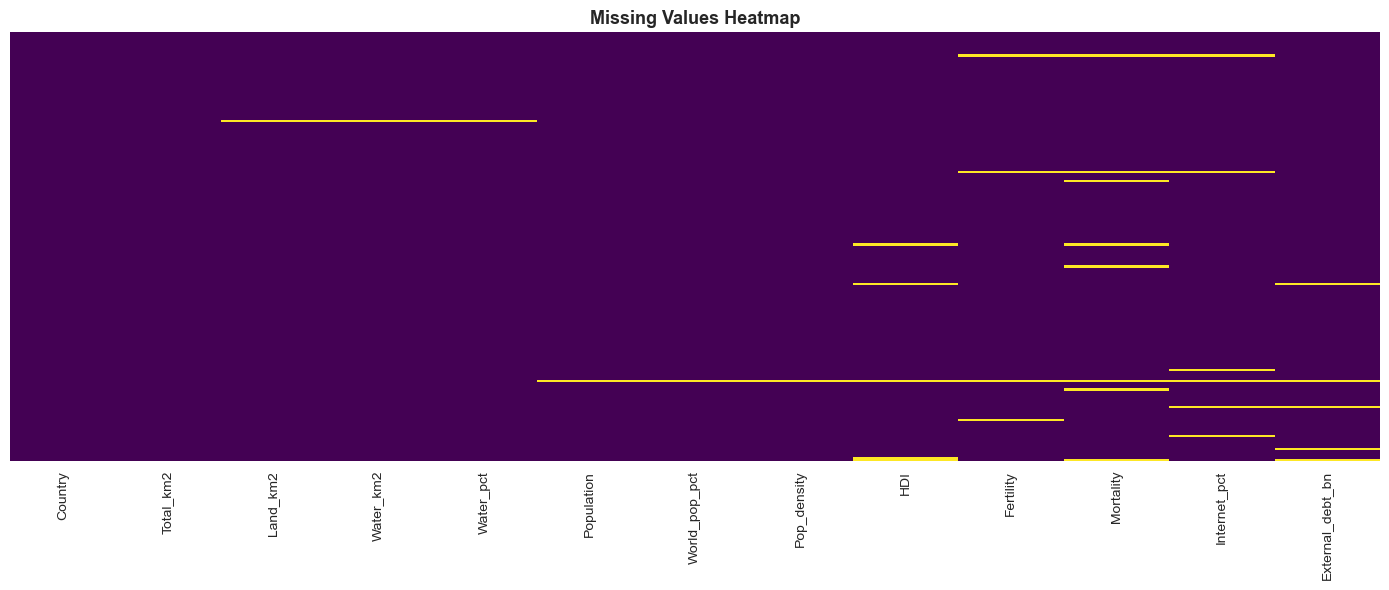

In [46]:
plt.figure(figsize=(14, 6))
sns.heatmap(df[rename_map.values()].isnull(), cbar=False,
            cmap='viridis', yticklabels=False)
plt.title('Missing Values Heatmap')
plt.tight_layout()
plt.show()

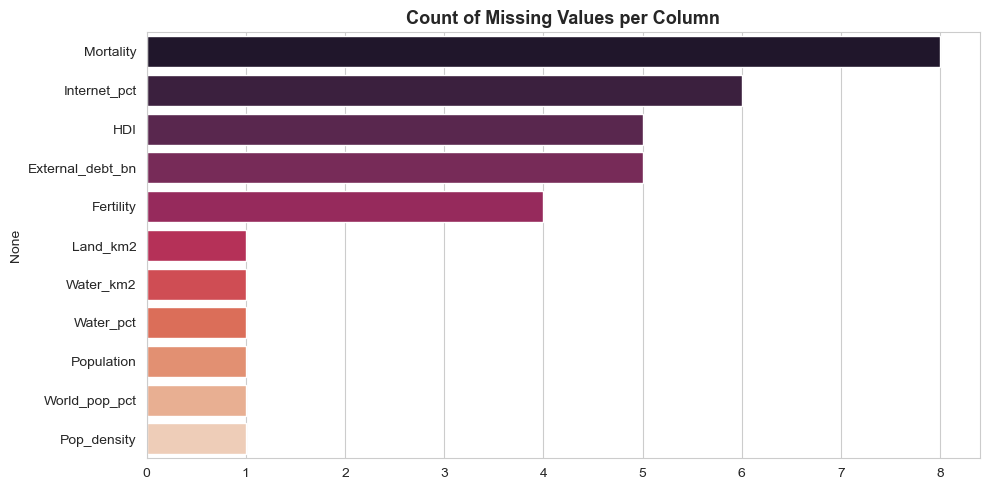

In [47]:
missing = df[rename_map.values()].isnull().sum().sort_values(ascending=False)
missing = missing[missing > 0]
if len(missing):
    plt.figure(figsize=(10, 5))
    sns.barplot(x=missing.values, y=missing.index, palette='rocket')
    plt.title('Count of Missing Values per Column')
    plt.tight_layout()
    plt.show()
else:
    print("No missing values.")